# 08 – Ring-Nebel (NGC 6720) mit `astropipe`

**Was:** Die komplette Pipeline – Daten laden, Registrierung, Streckung, Farbe, Export – auf ein zweites Objekt anwenden, diesmal mit den Funktionen aus dem Paket.

**Warum:** Der eigentliche Test, wie allgemein unser Code ist. Anderes Programm (1558, Cycle 1 GO, PI M. Barlow), andere Filter (4 statt 6), anderes Objekt. Alles, was hier hakt, zeigt eine Stelle, an der der Code noch zu sehr auf NGC 3132 zugeschnitten war.

**Ablauf mit Haltepunkten** (wie gestern: erst prüfen, dann weiter):
1. Daten suchen → **Größe prüfen** → laden
2. Registrierung + Sternkontrolle
3. Himmelsboxen → **Karte prüfen** → Streckung → **Parameter anpassen**
4. Farbe: A (chromatisch) und B (NASA) → **Wahl**
5. Export

**Ergebnis:** _(nach dem Ausführen eintragen)_

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from astropy.io import fits
from astropy.wcs import WCS
from scipy.ndimage import distance_transform_edt

from astropipe import bands, mast, registration, stretch, color, export

TARGET = "ngc6720"
PROGRAM = 1558
ROOT = Path("..")
RAW = ROOT / "data" / f"{TARGET}_nircam"
REPROJ = ROOT / "data" / f"{TARGET}_nircam_reproj_lw"
STRETCHED = ROOT / "data" / f"{TARGET}_nircam_stretched"
for d in (RAW, REPROJ, STRETCHED):
    d.mkdir(parents=True, exist_ok=True)

## 1. Daten suchen und Größe prüfen

Erwartet (laut Wesson et al. und NASA): vier NIRCam-Filter F162M, F212N, F300M, F335M in einem Bildfeld. Falls mehr i2d-Dateien auftauchen (z. B. mehrere Beobachtungen pro Filter), **hier anhalten** und die Liste ansehen.

In [2]:
obs, i2d = mast.find_i2d(PROGRAM, "NIRCAM/IMAGE")
print(len(obs), "observations,", len(i2d), "i2d products,", f"{mast.total_size_gb(i2d):.2f} GB")
obs["obs_id", "filters", "t_exptime", "target_name"]

4 observations, 4 i2d products, 1.79 GB


obs_id,filters,t_exptime,target_name
str37,str12,float64,str7
jw01558-o005_t001_nircam_clear-f335m,F335M,483.1559999999998,NGC6720
jw01558-o005_t001_nircam_f150w2-f162m,F150W2;F162M,483.1559999999998,NGC6720
jw01558-o005_t001_nircam_clear-f212n,F212N,483.1559999999998,NGC6720
jw01558-o005_t001_nircam_clear-f300m,F300M,483.1559999999998,NGC6720


In [3]:
i2d.sort("size")
for row in i2d:
    print(f"{row['productFilename']:<60} {row['size'] / 1e6:8.1f} MB  {row['dataRights']}")

jw01558-o005_t001_nircam_clear-f335m_i2d.fits                   150.1 MB  PUBLIC
jw01558-o005_t001_nircam_clear-f300m_i2d.fits                   150.1 MB  PUBLIC
jw01558-o005_t001_nircam_f150w2-f162m_i2d.fits                  744.6 MB  PUBLIC
jw01558-o005_t001_nircam_clear-f212n_i2d.fits                   744.9 MB  PUBLIC


In [4]:
DOWNLOAD = False   # set True after checking the list above
if DOWNLOAD:
    manifest = mast.download(i2d, RAW, max_gb=5.0)
    display(manifest["Local Path", "Status"])
I2D = {bands.band_from_header(fits.getheader(f, 0)): f for f in sorted(RAW.glob("*_i2d.fits"))}
BANDS = bands.sort_bands(I2D)
print(BANDS)

['F162M', 'F212N', 'F300M', 'F335M']


## 2. Registrierung und Sternkontrolle

Gleiche Entscheidungen wie bei NGC 3132: gemeinsames Raster mit 0,063″/px (Langwellen-Auflösung), Norden oben, `reproject_adaptive`. Bereits vorhandene Ergebnisse werden wiederverwendet.

In [5]:
USE_DESTRIPED = True
DS = ROOT / "data" / f"{TARGET}_nircam_destriped_local"
if USE_DESTRIPED:
    for b in list(I2D):
        cand = DS / I2D[b].name.replace("_i2d", "_destriped_i2d")
        if cand.exists():
            I2D[b] = cand
print({b: p.name for b, p in I2D.items()})
PREFIX = f"{TARGET}_lw_dsl" if USE_DESTRIPED else f"{TARGET}_lw"

for b in BANDS:
    h = fits.getheader(I2D[b], extname="SCI")
    print(f"{b:<6} {h['NAXIS2']} x {h['NAXIS1']} px, {registration.pixel_scale_arcsec(WCS(h))[0]:.4f}″/px, {h.get('BUNIT')}")

wcs_out, shape_out = registration.target_grid(I2D.values(), 0.063)
print("target grid:", shape_out)
REPROJ_FILES = registration.reproject_all({b: I2D[b] for b in BANDS}, wcs_out, shape_out, REPROJ, PREFIX)

{'F212N': 'jw01558-o005_t001_nircam_clear-f212n_destriped_i2d.fits', 'F300M': 'jw01558-o005_t001_nircam_clear-f300m_destriped_i2d.fits', 'F335M': 'jw01558-o005_t001_nircam_clear-f335m_destriped_i2d.fits', 'F162M': 'jw01558-o005_t001_nircam_f150w2-f162m_destriped_i2d.fits'}
F162M  4815 x 4830 px, 0.0308″/px, MJy/sr
F212N  4816 x 4831 px, 0.0307″/px, MJy/sr
F300M  2310 x 2317 px, 0.0630″/px, MJy/sr
F335M  2310 x 2317 px, 0.0630″/px, MJy/sr
target grid: (3311, 3312)
F162M     23.8 s -> ngc6720_lw_dsl_f162m_reproj.fits
F212N     23.8 s -> ngc6720_lw_dsl_f212n_reproj.fits
F300M      9.2 s -> ngc6720_lw_dsl_f300m_reproj.fits
F335M      9.3 s -> ngc6720_lw_dsl_f335m_reproj.fits


In [6]:
raw = {b: fits.getdata(REPROJ_FILES[b]).astype(np.float32) for b in BANDS}
REF = BANDS[-1]   # longest wavelength as reference
off = registration.star_offsets(raw, REF)
for b in BANDS:
    o = off[b]
    print(f"{b:<6} median offset vs {REF}: {np.median(o):.2f} px ({len(o)} stars)" if o else f"{b:<6} no stars measured")

F162M  median offset vs F335M: 0.16 px (8 stars)
F212N  median offset vs F335M: 0.05 px (9 stars)
F300M  median offset vs F335M: 0.02 px (9 stars)
F335M  median offset vs F335M: 0.00 px (9 stars)


## 3. Sättigungslücken, Himmelsboxen, Hintergrund

**Achtung, anders als bei NGC 3132:** Soweit ich weiß, hat der Ring-Nebel einen schwachen Halo, der weit über den hellen Ring hinausreicht. Es ist gut möglich, dass das Bildfeld **keinen wirklich leeren Himmel** enthält. Dann würden die „Himmelsboxen“ schwaches Nebellicht als Hintergrund abziehen. Die Karte und die Scores unten deshalb besonders kritisch ansehen.

filled saturated px: {'F162M': 146, 'F212N': 51, 'F300M': 95, 'F335M': 85}
valid in all bands: 46.6 %
box 0: y= 1875 x= 2625 score=-0.0734
box 1: y= 2475 x= 1800 score=-0.0038
box 2: y= 1125 x= 2325 score=0.0033
box 3: y= 2100 x= 2175 score=0.0181
box 4: y=  450 x= 1575 score=0.0354
box 5: y= 2400 x= 1125 score=0.0475


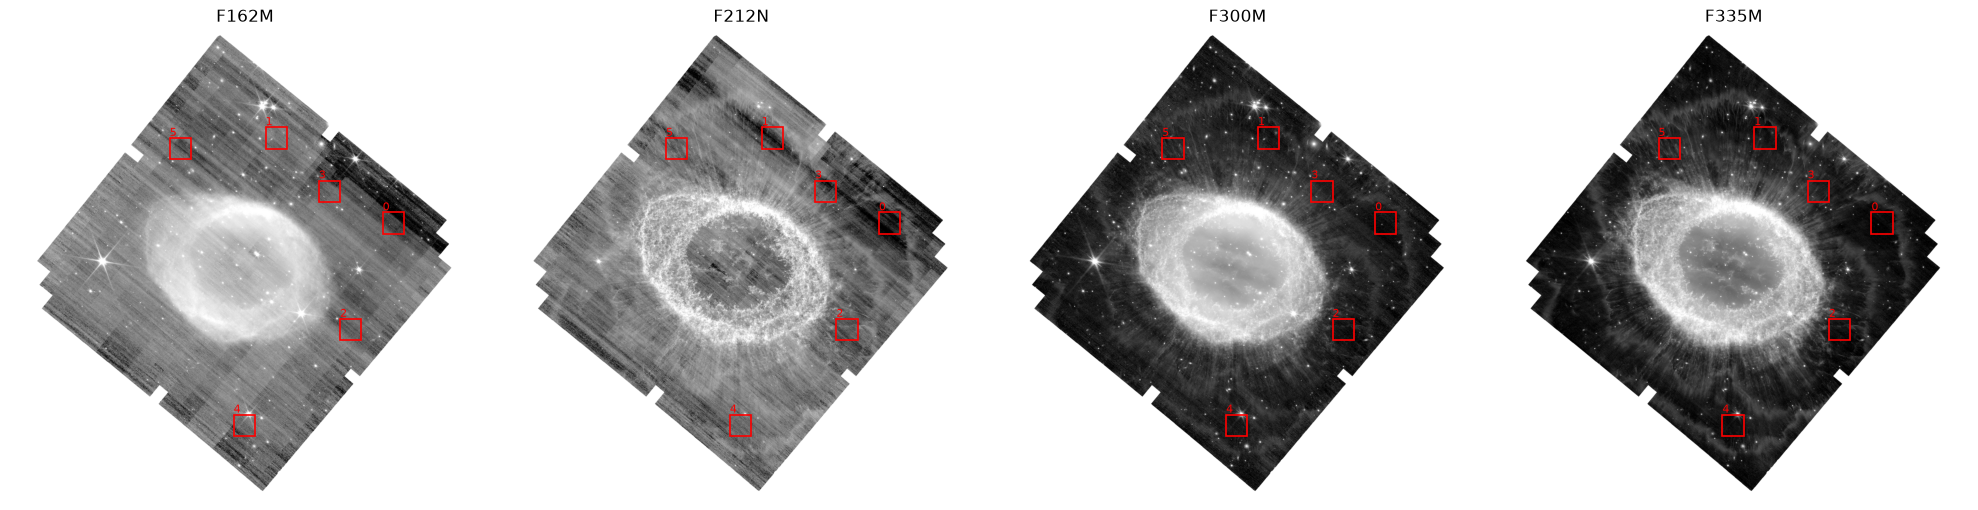

In [7]:
imgs, filled = {}, {}
for b in BANDS:
    imgs[b], filled[b] = stretch.fill_saturated_holes(raw[b], max_hole_px=2000)
valid = stretch.common_valid(imgs)
print("filled saturated px:", filled)
print(f"valid in all bands: {100 * valid.mean():.1f} %")

BOX, EDGE, NBOX, MINSEP = 150, 150, 6, 500
boxes, scores = stretch.find_sky_boxes(imgs, valid, BOX, EDGE, NBOX, MINSEP)
for i, (bx, s) in enumerate(zip(boxes, scores)):
    print(f"box {i}: y={bx[0]:5d} x={bx[1]:5d} score={s:.4f}")

def preview(img, a=0.05):
    v = img[valid]
    lo, hi = np.percentile(v, [1, 99.5])
    y = np.clip((img - lo) / (hi - lo), 0, 1)
    return np.where(valid, stretch.asinh_stretch(y, a), np.nan)

fig, axes = plt.subplots(1, len(BANDS), figsize=(5 * len(BANDS), 5))
for ax, b in zip(axes, BANDS):
    ax.imshow(preview(imgs[b]), origin="lower", cmap="gray")
    for i, (y, x) in enumerate(boxes):
        ax.add_patch(Rectangle((x, y), BOX, BOX, fill=False, ec="red", lw=1.2))
        ax.text(x, y + BOX + 15, str(i), color="red", fontsize=8)
    ax.set_title(b); ax.axis("off")
plt.tight_layout()

In [8]:
boxes_used = [bx for bx, s in zip(boxes, scores) if s > 0]   # rule: negative score = detector artefact
print(len(boxes_used), "of", len(boxes), "boxes used:", boxes_used)

stats = stretch.sky_stats(imgs, boxes_used, BOX)
print(f"{'band':<6}{'bkg':>9}{'noise':>9}{'spread/noise':>14}")
for b in BANDS:
    s = stats[b]
    print(f"{b:<6}{s['bkg']:9.4f}{s['noise']:9.4f}{s['spread'] / s['noise']:14.2f}")

4 of 6 boxes used: [(1125, 2325), (2100, 2175), (450, 1575), (2400, 1125)]
band        bkg    noise  spread/noise
F162M   -0.0211   0.0978          0.55
F212N   -0.6550   0.8518          1.18
F300M    0.1273   0.0327          1.80
F335M    0.1929   0.0449          2.34


## 4. Streckung

Startwerte wie bei NGC 3132 vor dem Feintuning. Zur Erinnerung: größeres `black_k` → Hintergrund heller/rauschiger; negatives `black_k` → Rauschen wird schwarz.

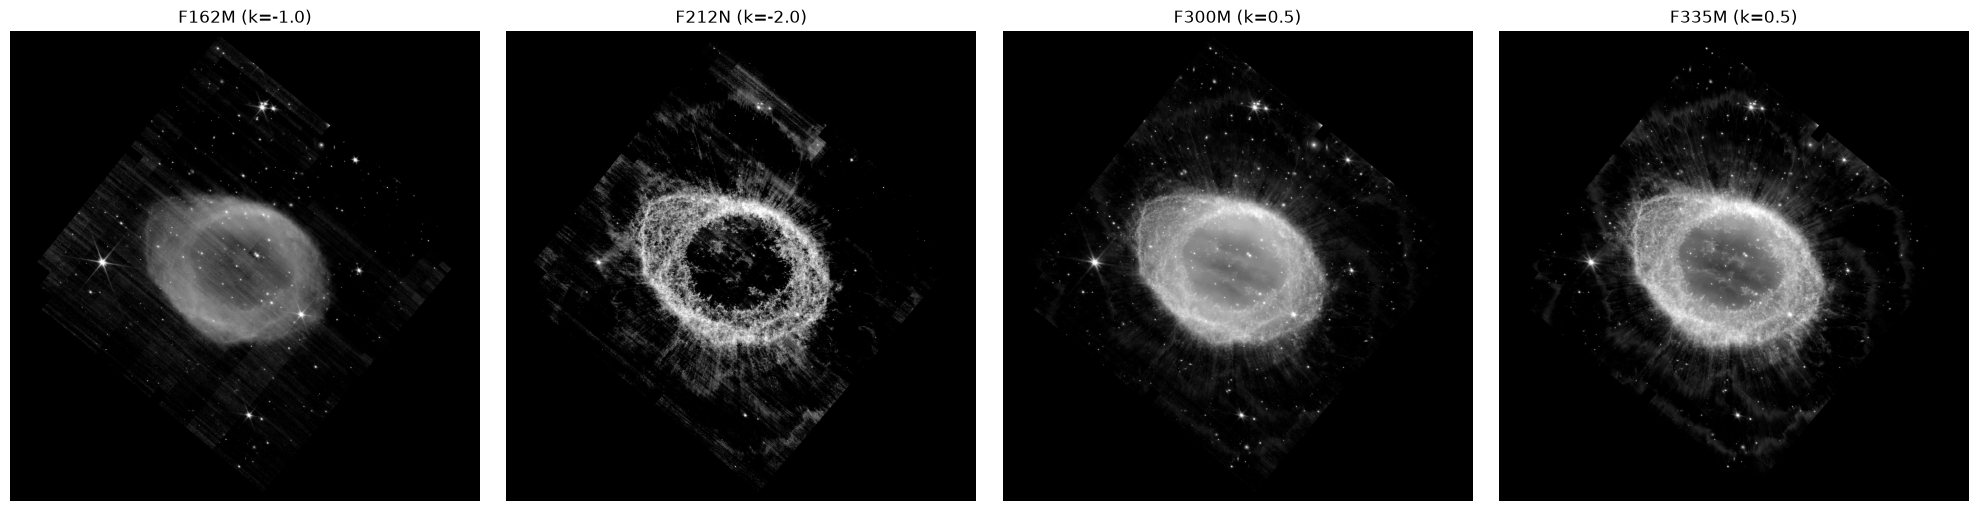

In [9]:
PARAMS = {
    "F162M": dict(black_k=-1.0, white_pct=99.9, a=0.05),
    "F212N": dict(black_k=-2.0, white_pct=99.9, a=0.05),
    "F300M": dict(black_k=0.5,  white_pct=99.9, a=0.05),
    "F335M": dict(black_k=0.5,  white_pct=99.9, a=0.05),
}

stretched, levels = stretch.stretch_all(imgs, valid, stats, PARAMS)
fig, axes = plt.subplots(1, len(BANDS), figsize=(5 * len(BANDS), 5))
for ax, b in zip(axes, BANDS):
    ax.imshow(stretched[b], origin="lower", cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{b} (k={PARAMS[b]['black_k']})"); ax.axis("off")
plt.tight_layout()

## 5. Farbe

Farben werden jetzt als **Farbwinkel (und Sättigung)** festgelegt und so gespeichert – exakt reproduzierbar (Lehre aus Notebook 07).
- **A – chromatisch:** automatisch, gleichmäßig von 240° (blau) bis 0° (rot) nach Wellenlänge.
- **B – NASA:** F162M blau (240°), F212N cyan (180°), F300M grün (120°), F335M rot (0°). Ebenfalls chromatisch, nur mit anderen Abständen.

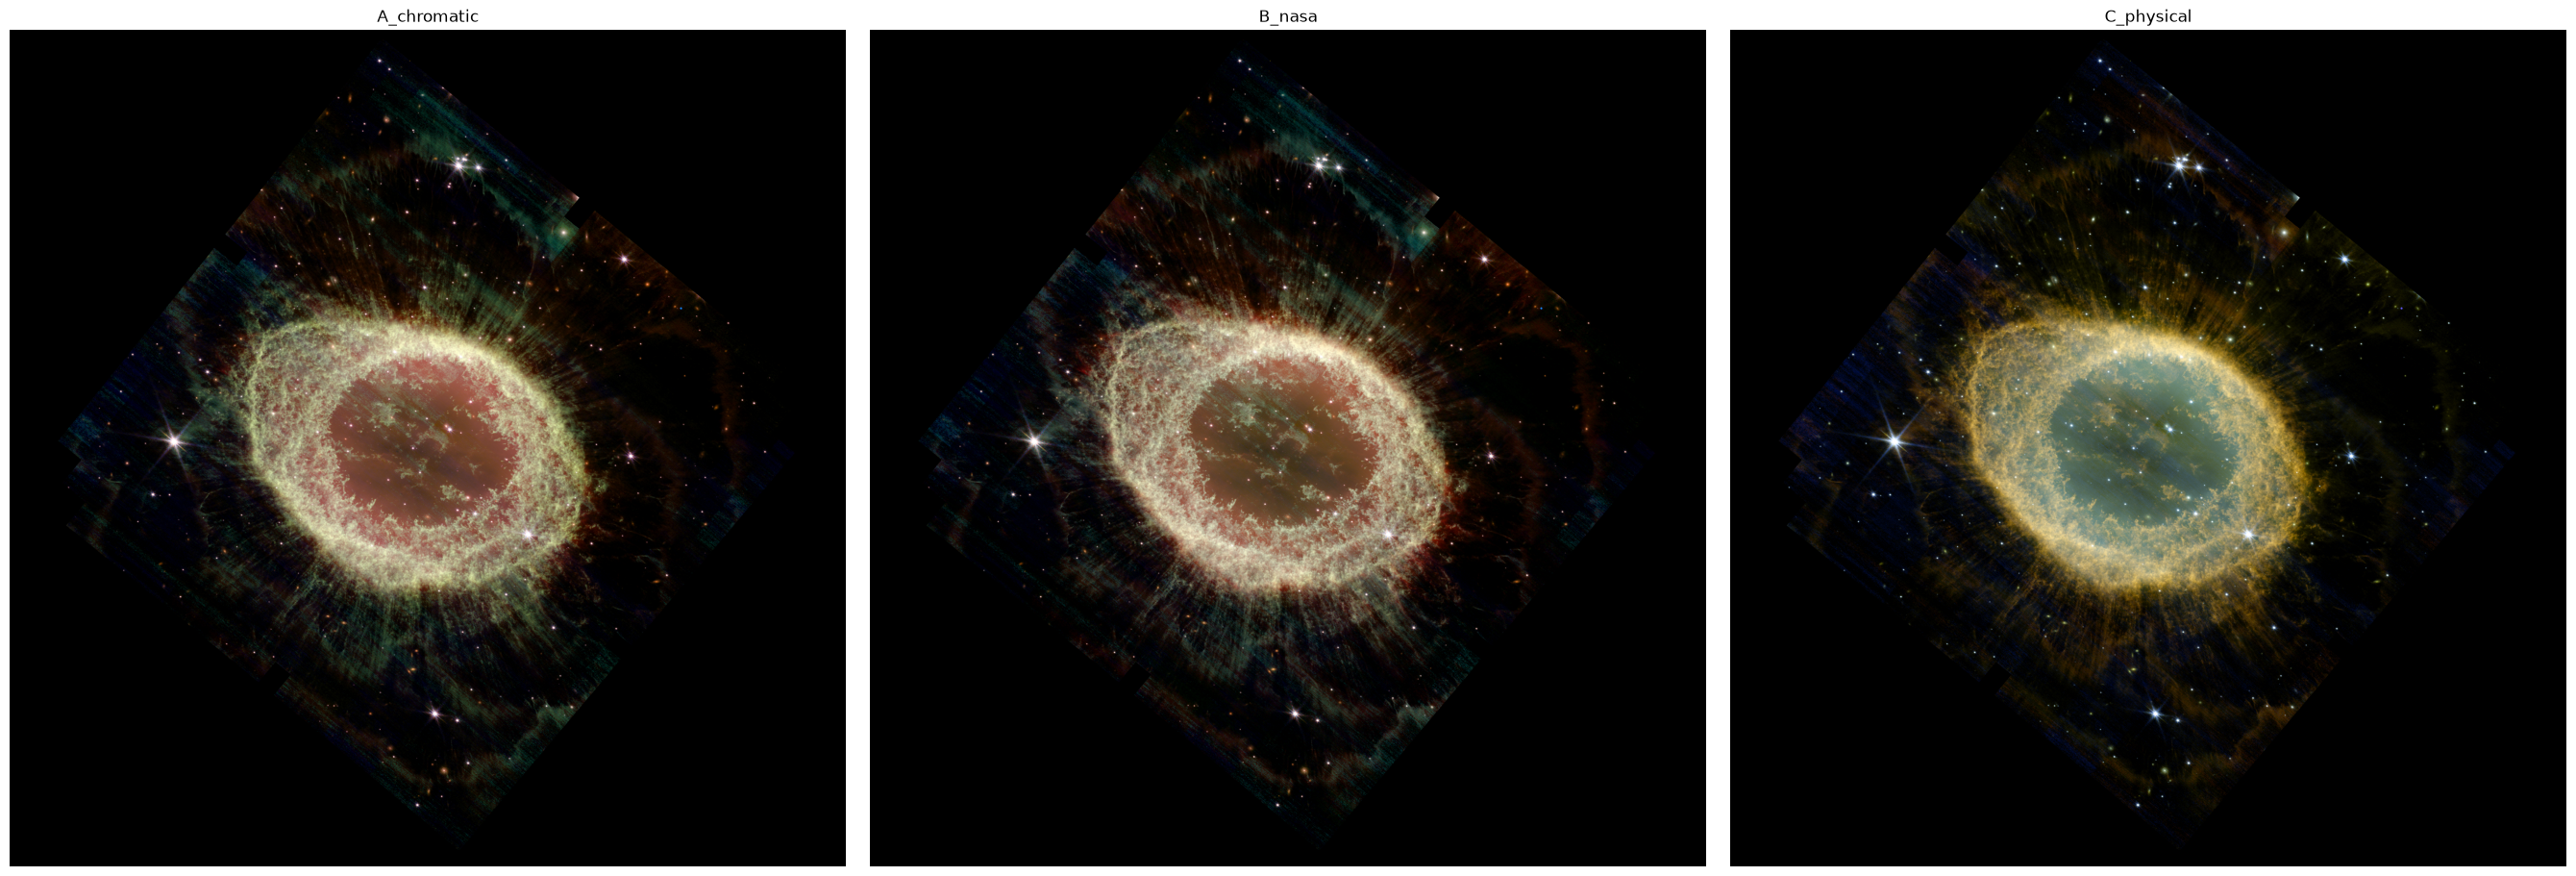

In [10]:
n = len(BANDS)
HUES = {
    "A_chromatic": {b: 240 - i * 240 / (n - 1) for i, b in enumerate(BANDS)},
    "B_nasa": {"F162M": 240, "F212N": 180, "F300M": 120, "F335M": 0},
    "C_physical": {"F162M": 210, "F212N": 15, "F300M": 60, "F335M": 40},
}
SATS = {name: {} for name in HUES}
WEIGHTS = {name: {} for name in HUES}

rgbs = {}
fig, axes = plt.subplots(1, len(HUES), figsize=(9 * len(HUES), 9))
for ax, name in zip(np.atleast_1d(axes), HUES):
    mapping = color.mapping_from_degrees(HUES[name], SATS[name])
    rgbs[name] = color.compose(stretched, mapping, WEIGHTS[name])
    ax.imshow(rgbs[name], origin="lower")
    ax.set_title(name); ax.axis("off")
plt.tight_layout()

## 6. Parameter speichern

Stretch- und Farbparameter in `params/ngc6720_*.json` (im Git), gestreckte Bilder nach `data/` (nicht im Git).

In [11]:
rec_stretch = {
    "input": str(REPROJ),
    "saturated_holes_filled_px": filled,
    "sky_boxes": {"size_px": BOX, "edge_margin_px": EDGE, "min_sep_px": MINSEP, "yx": [list(map(int, b)) for b in boxes_used]},
    "stretch": "asinh: out = asinh(y/a)/asinh(1/a), y = clip((img - bkg - black)/(white - black), 0, 1)",
    "per_band": {b: {**PARAMS[b], **stats[b], **levels[b]} for b in BANDS},
}
(ROOT / "params" / f"{TARGET}_stretch.json").write_text(json.dumps(rec_stretch, indent=2))
rec_color = {"mixing": "RGB = sum(w*img*colour) / sum(w*colour) per channel; colour = HSV(hue, sat, 1)",
             "variants": {name: {"hue_deg": HUES[name], "saturation": SATS[name], "weights": WEIGHTS[name]}
                          for name in HUES}}
(ROOT / "params" / f"{TARGET}_color.json").write_text(json.dumps(rec_color, indent=2))
for b in BANDS:
    fits.writeto(STRETCHED / f"{TARGET}_{b.lower()}_stretched.fits", stretched[b],
                 fits.getheader(REPROJ_FILES[b]), overwrite=True)
print("saved")

saved


## 7. Export (gewählte Variante)

Erst ausführen, wenn Streckung und Farbe feststehen. Die Bildunterschrift bitte vor dem Export ergänzen (Farbtabelle, was die Filter zeigen – soweit belastbar).

centre (1671, 1608), crop 1562 x 1172 px = 1.64′ x 1.23′, north up: True, east left: True


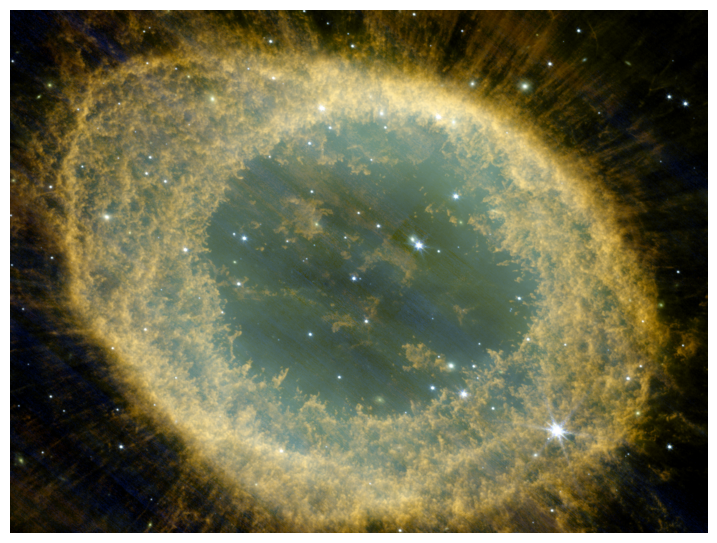

In [12]:
VARIANT = "C_physical"   # or "A_chromatic" / "B_nasa"
MARGIN = 120
AUTHOR = "Tritium13"

rgb = rgbs[VARIANT]
inner = distance_transform_edt(valid) > MARGIN
center = export.nebula_center(stretched[BANDS[-1]], valid)
ASPECT = 4 / 3   # width / height – the ring is wider than tall
half_h, half_w = export.largest_rect(inner, center, aspect=ASPECT)
cy, cx = center
crop = np.s_[cy - half_h:cy + half_h, cx - half_w:cx + half_w]
north_up, east_left = export.orientation(wcs_out, cy, cx)
size_w, size_h = 2 * half_w * 0.063 / 60, 2 * half_h * 0.063 / 60
print(f"centre {center}, crop {2 * half_w} x {2 * half_h} px = {size_w:.2f}′ x {size_h:.2f}′, north up: {north_up}, east left: {east_left}")

plt.figure(figsize=(9, 9)); plt.imshow(rgb[crop], origin="lower"); plt.axis("off");

In [15]:
COLOR_NAMES = {"F162M": "blue", "F212N": "orange-red", "F300M": "yellow", "F335M": "gold"}
CONTENT = {"F162M": "mainly continuum, presumably free-free emission from ionised gas, plus hydrogen recombination lines",
           "F212N": "mainly molecular hydrogen (H2)",
           "F300M": "continuum, H2 and hydrogen lines (mixed)",
           "F335M": "continuum and H2, plus the 3.3 µm PAH band (mixed)"}
rows = "\n".join(f"| {b} | {COLOR_NAMES[b]} | {CONTENT[b]} |" for b in BANDS)
orient = "north up, east left" if (north_up and east_left) else "ORIENTATION TO BE CHECKED"

caption = f"""# Ring Nebula (NGC 6720, M57) – JWST NIRCam

Planetary nebula in the constellation Lyra, observed with the Near-Infrared Camera (NIRCam) of the James Webb Space Telescope (Cycle 1 GO programme 1558, PI M. Barlow). Field of view ≈ {size_w:.1f} × {size_h:.1f} arcmin, {orient}.

## Colour assignment ({VARIANT}: chosen freely, grouped by physical origin, not by wavelength)

| Filter | Colour | Mainly traces |
|---|---|---|
{rows}

Filter contents follow the estimates in Wesson et al. 2024 (MNRAS; arXiv:2308.09027, Table 1), which refer to part of the bright ring. The recorded light is infrared; all colours are an assignment, not "true" colours.

## Processing

Calibrated stage-3 images (`_i2d.fits`) from MAST → row destriping of all four filters in 512-px column blocks using a local background model (16-px median cells; approximate correction of detector readout stripes – residual fine stripes and detector blocks remain) → common grid (0.063″/px, `reproject_adaptive`) → background subtraction from four sky boxes (the faint halo fills most of the field, so the background is relative) → asinh stretch per filter (each filter normalised to its own white point) → additive colour mixing. Saturated star cores filled with white. No local adjustments. Parameters: `params/{TARGET}_stretch.json`, `params/{TARGET}_color.json`. Code: `src/astropipe`.

## Credits

Data: NASA, ESA, CSA, STScI (programme 1558, PI M. Barlow), retrieved via MAST. Processing: {AUTHOR}.
"""
print(caption)

# Ring Nebula (NGC 6720, M57) – JWST NIRCam

Planetary nebula in the constellation Lyra, observed with the Near-Infrared Camera (NIRCam) of the James Webb Space Telescope (Cycle 1 GO programme 1558, PI M. Barlow). Field of view ≈ 1.6 × 1.2 arcmin, north up, east left.

## Colour assignment (C_physical: chosen freely, grouped by physical origin, not by wavelength)

| Filter | Colour | Mainly traces |
|---|---|---|
| F162M | blue | mainly continuum, presumably free-free emission from ionised gas, plus hydrogen recombination lines |
| F212N | orange-red | mainly molecular hydrogen (H2) |
| F300M | yellow | continuum, H2 and hydrogen lines (mixed) |
| F335M | gold | continuum and H2, plus the 3.3 µm PAH band (mixed) |

Filter contents follow the estimates in Wesson et al. 2024 (MNRAS; arXiv:2308.09027, Table 1), which refer to part of the bright ring. The recorded light is infrared; all colours are an assignment, not "true" colours.

## Processing

Calibrated stage-3 images (`_i2d.fits`) f

In [16]:
EXPORT = True   # set True when caption and crop are final
if EXPORT:
    for p in export.save_outputs(rgb[crop], caption, f"{TARGET}_nircam_{VARIANT}",
                                 ROOT / "output" / "full_res", ROOT / "output"):
        print(f"{p.stat().st_size / 1e6:7.2f} MB  {p}")

  10.99 MB  ../output/full_res/ngc6720_nircam_C_physical_16bit.tif
   2.93 MB  ../output/full_res/ngc6720_nircam_C_physical_full.png
   0.44 MB  ../output/ngc6720_nircam_C_physical_web.jpg
   0.00 MB  ../output/ngc6720_nircam_C_physical_caption.md


## Fazit

- **Paket im Praxistest:** Download, Filtererkennung (auch `F150W2;F162M` → F162M), Registrierung (Versatz 0,02–0,16 px), Sättigungslücken und Export liefen ohne Anpassung. Angepasst werden musste vor allem der Umgang mit Streifen und Hintergrund – Stellen, an denen der Code auf NGC 3132 zugeschnitten war.
- **Kein leerer Himmel:** Der Halo mit seinen Bögen füllt das Bildfeld. Der Hintergrund aus den Himmelsboxen ist daher relativ (enthält Halo-Licht).
- **Himmelsboxen:** zwei Boxen mit negativem Score (dunkle Detektorbänder) verworfen → Regel „Score > 0“, 4 von 6 genutzt.
- **Notebook-Falle:** Die Box-Liste wurde beim wiederholten Ausführen einer Zelle mehrfach gekürzt (erst 3, dann 1 Box). Lösung: gefilterte Liste unter neuem Namen (`boxes_used`) und Ergebnisse nur nach „Restart Kernel and Run All“ werten.
- **Streifen:** kurze Belichtung (483 s) → deutliche Ausleser-Streifen; Korrektur vor der Registrierung mit lokalem Hintergrundmodell (Notebook 08b).
- **Farbe:** A und B (beide chromatisch) nahezu gleich, eher blass (lachsfarbener Innenraum). **C – physikalisch gruppiert** nach Wesson et al. 2024 (F162M ionisiertes Gas → blau, F212N H₂ → orange-rot, F300M/F335M gemischt → gelb/gold): bläulicher Innenraum, goldener Ring. Der Ring wirkt golden statt rot, weil auch F300M/F335M viel H₂ enthalten – physikalisch stimmig.
- **Ausschnitt:** Der gültige Bereich ist eine Raute (≈ 45° gedreht); Querformat 4:3 zeigt mit 1,64′ × 1,23′ deutlich mehr vom Ring als das Quadrat (1,31′).
- **Bekannte Grenzen:** feine Reststreifen und Detektor-Blöcke im Innenraum; Filterinhalte gelten laut Quelle für einen Teil des Rings.